# Урок 8 — От цепочки действий к первому обучению

[План курса](../../README_ru.md) · [Предыдущий урок](lesson-07.ipynb) · [English](../en/lesson-08.ipynb) · [Дальше: целая картинка](lesson-09.ipynb)

В прошлом уроке мы смотрели, как меняется ошибка при небольшом движении параметра. Для одного центра два дополнительных расчёта — не проблема. Но в картинке скоро будут десятки пятен, и у каждого окажется несколько своих чисел. Пересчитывать всю картинку отдельно для каждого числа становится дороговато.

При этом сама картинка уже получилась из знакомых действий: вычитания, деления, умножения, экспоненты. Можно запомнить эти действия, а затем пройти по ним в обратную сторону. Так появится градиент, а из него — следующий шаг обучения.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import math
import numpy as np
import torch
from IPython.display import display

course_root = next(folder for folder in [Path.cwd(), *Path.cwd().parents]
                   if (folder / "training_math.py").is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from training_math import (chain_example, autograd_check, fit_one_gaussian,
                           make_target, initialize, render_torch, projected_step,
                           fit_image, parameters_scene, load_image, small_cpu_work)
from training_demos import (chain_figure, learning_figure, autograd_lab,
                            demo_fit, fitting_figure, detail_figure, fitting_lab)
LANG = 'ru'

## 1. Колокол начинает двигаться сам

Тёмная кривая — образец с центром $1.5$ и шириной $1$. Синяя — наша попытка. У неё та же ширина, но начальный центр равен $-1$. В обучении меняется только центр; высоту и ширину пока фиксируем.

Поле «Шаг» показывает состояние после выбранного количества обновлений. Рядом — ошибка и путь центра. При нулевом размере шага ничего не движется. При слишком большом возможны прыжки через нужное положение. Этот опыт использует всю кривую, а следующий числовой разбор сначала возьмёт только одну её точку.

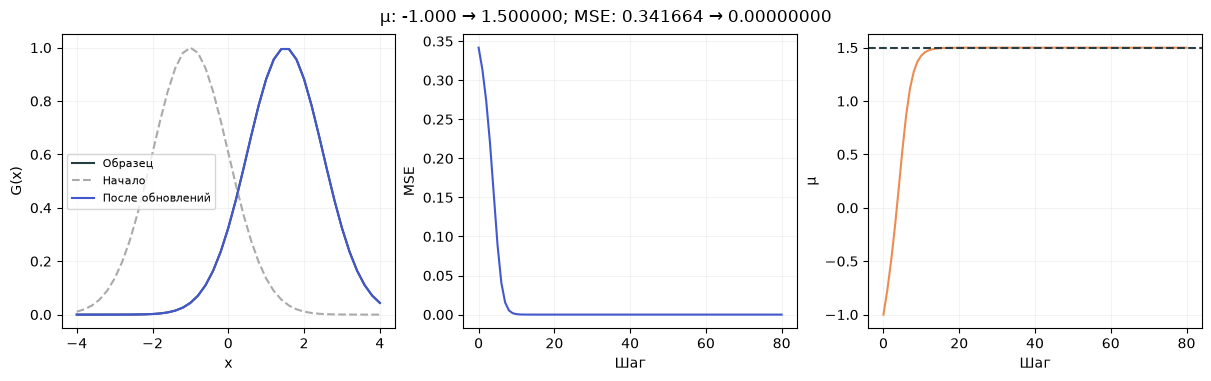

In [2]:
display(learning_figure(language=LANG))
display(autograd_lab(language=LANG))

## 2. Один расчёт, семь коротких действий

Возьмём точку $x=1$, центр $\mu=0$ и ширину $\sigma=1$. В этой точке образец имеет значение $y=0.8$. Буква $y$ здесь обозначает нужный вес, а не вертикальную координату изображения. Все веса безразмерны. Координаты и ширина измеряются в одних условных единицах.

Наша гауссиана даёт $G$. Остаток $r$ — это наше значение минус нужное. Ошибка $L$ — квадрат остатка. Пока измерение одно, поэтому усреднять нечего.

| Действие | Подстановка | Результат |
|---|---|---|
| $d=x-\mu$ | $1-0$ | $1$ |
| $u=d/\sigma$ | $1/1$ | $1$ |
| $q=u\cdot u$ | $1\cdot1$ | $1$ |
| $t=-q/2$ | $-1/2$ | $-0.5$ |
| $G=\exp(t)$ | $\exp(-0.5)$ | $0.606530660$ |
| $r=G-y$ | $0.606530660-0.8$ | $-0.193469340$ |
| $L=r\cdot r$ | $(-0.193469340)^2$ | $0.037430386$ |

Получилась дорожка: центр → смещение → относительное смещение → квадрат → показатель → вес → остаток → ошибка. Это и есть **граф вычислений**. Здесь он похож на цепочку. В более сложной программе пути могут расходиться и снова соединяться.

Нужный вес больше нашего. При движении центра вправо точка $x=1$ становится ближе к вершине, и вес растёт. Значит, возле $\mu=0$ движение вправо должно уменьшать ошибку. Градиент позволит проверить это числами.

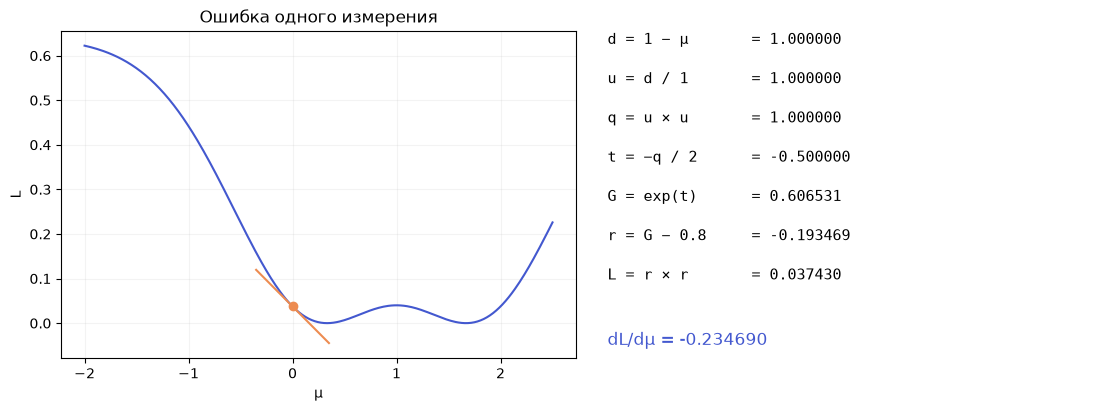

d 1.0
u 1.0
q 1.0
t -0.5
weight 0.6065306597126334
residual -0.19346934028736662
loss 0.03743038563122886
local [-0.38693868057473324, 0.6065306597126334, -0.5, 2.0, 1.0, -1.0]
gradient -0.23469017319732888


In [3]:
display(chain_figure(language=LANG))
for name, value in chain_example().items():
    print(name, value)

## 3. У каждого действия есть свой маленький наклон

Обозначение $dL/dr$ читается как «производная ошибки по остатку». Здесь буква $d$ возле $L$ и $r$ — часть записи производной, не наше смещение из таблицы. Смысл такой: при маленьком изменении остатка на $\Delta r$ ошибка меняется примерно на $(dL/dr)\Delta r$.

Начнём с квадрата. Пусть вход равен $a$, а маленькое изменение — $h$, причём $h\ne0$:

$$
\frac{(a+h)^2-a^2}{h}
=\frac{a^2+2ah+h^2-a^2}{h}
=2a+h.
$$

Раскрыли скобки, сократили одинаковые квадраты и разделили оставшиеся слагаемые на $h$. При всё меньшем $h$ добавка $h$ стремится к нулю, а наклон — к $2a$. Поэтому для $L=r^2$ наклон равен $2r$, а для $q=u^2$ — $2u$. В нашем примере это $-0.386938681$ и $2$.

Остальные простые действия видны прямо из изменения входа:

- В $r=G-y$ образец $y$ фиксирован. Прибавка $h$ к $G$ даёт ту же прибавку к $r$: наклон $1$.
- В $t=-q/2$ прибавка $h$ к $q$ становится прибавкой $-h/2$ к $t$: наклон $-1/2$.
- В $u=d/\sigma$ ширина фиксирована. Прибавка $h$ к $d$ превращается в $h/\sigma$: наклон $1/\sigma=1$.
- В $d=x-\mu$ точка $x$ фиксирована. Прибавка $h$ к центру отнимает $h$ у смещения: наклон $-1$.

Осталась экспонента. Её особенность — наклон в точке $t$ равен самому значению $\exp(t)$. Это не свойство любой кривой. Для экспоненты:

$$
\frac{\exp(t+h)-\exp(t)}{h}
=\exp(t)\frac{\exp(h)-1}{h}.
$$

Мы использовали $\exp(t+h)=\exp(t)\exp(h)$ и вынесли общий множитель. Отношение справа приближается к $1$ при $h$, приближающемся к нулю: примерно $1.051709$ для $h=0.1$, $1.005017$ для $0.01$, $1.000500$ для $0.001$. В пределе остаётся $\exp(t)$. При $t=-0.5$ местный наклон равен $0.606530660$.

Это свойство натуральной экспоненты можно и вывести из её определения через бесконечный ряд. Здесь достаточно понимать, какое изменение оно описывает, и проверить его малыми сдвигами. В коде используются производные самих операций, а не эти приближённые отношения.

In [4]:
for h in [0.1, 0.01, 0.001, 0.0001]:
    print(f"h={h:g}: expm1(h)/h = {math.expm1(h) / h:.9f}")

h=0.1: expm1(h)/h = 1.051709181
h=0.01: expm1(h)/h = 1.005016708
h=0.001: expm1(h)/h = 1.000500167
h=0.0001: expm1(h)/h = 1.000050002


## 4. Почему наклоны перемножаются

Если первое действие превращает маленькое изменение входа в изменение вдвое больше, а второе увеличивает его ещё втрое, весь путь увеличит его примерно в шесть раз. Числа $2$ и $3$ — местные наклоны. Для маленьких изменений последовательно получаем $\Delta b\approx2\Delta a$ и $\Delta c\approx3\Delta b\approx6\Delta a$.

Это **правило цепочки**. Знак приближения относится к конечным изменениям. В пределе бесконечно малого изменения получается точное равенство производных. Правило описывает гладкий участок, а не обещает точный результат большого скачка.

Пройдём от ошибки обратно к центру. На старте чувствительность $L$ к самому себе равна $1$. Дальше каждый наклон домножает уже накопленное число:

| Обратный переход | Множитель | Накопленная чувствительность |
|---|---|---|
| $L\to r$ | $2r=-0.386938681$ | $-0.386938681$ |
| $r\to G$ | $1$ | $-0.386938681$ |
| $G\to t$ | $G=0.606530660$ | $-0.234690173$ |
| $t\to q$ | $-0.5$ | $0.117345087$ |
| $q\to u$ | $2u=2$ | $0.234690173$ |
| $u\to d$ | $1/\sigma=1$ | $0.234690173$ |
| $d\to\mu$ | $-1$ | $-0.234690173$ |

В компактной записи:

$$
\frac{dL}{d\mu}
=\frac{dL}{dr}\frac{dr}{dG}\frac{dG}{dt}
 \frac{dt}{dq}\frac{dq}{du}\frac{du}{dd}\frac{dd}{d\mu}
=2(G-y)G\frac{x-\mu}{\sigma^2}.
$$

Последняя дробь получилась так: множители $(-1/2)\cdot2u\cdot(1/\sigma)\cdot(-1)$ дают $u/\sigma$. А $u=(x-\mu)/\sigma$, поэтому ещё одно деление на ширину даёт $(x-\mu)/\sigma^2$. Каждый кусок короткой формулы уже был в таблице.

Градиент отрицательный. При положительном маленьком изменении центра ошибка уменьшается. Например, линейная оценка для $\Delta\mu=0.01$ даёт изменение $-0.234690173\cdot0.01=-0.002346902$. Это изменение ошибки, не новая ошибка: приблизительно получится $0.037430386-0.002346902=0.035083484$. Прямой пересчёт немного отличается, потому что наклон меняется по дороге.

In [5]:
start = chain_example()
shift = 0.01
print("linear estimate:", start["loss"] + start["gradient"] * shift)
print("direct evaluation:", chain_example(mu=shift)["loss"])

linear estimate: 0.03508348389925557
direct evaluation: 0.035120347809244036


## 5. То же самое руками PyTorch

**Тензор** здесь — число, вектор или прямоугольная таблица чисел. В первой строке будет тензор из одного числа, то есть скаляр. `requires_grad=True` помечает величину, для которой нужен градиент. Флаг не обучает её и ничего сам не двигает.

`float64` хранит числа примерно с 15–16 значащими десятичными цифрами. Для небольших проверок это удобно: ошибка округления меньше мешает сравнению с маленьким сдвигом. В больших моделях часто используют меньшую точность, но это отдельный выбор.

Во время вычислений PyTorch строит граф. Вызов `backward()` идёт по нему назад и складывает вклады в `mu.grad`. Метод `item()` достаёт обычное число только для вывода. Если извлечь число посередине вычислений и продолжить расчёт с ним, связь с графом потеряется.

In [6]:
mu = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
x, sigma, target = 1.0, 1.0, 0.8
d = x - mu
u = d / sigma
q = u * u
t = -q / 2
weight = torch.exp(t)
residual = weight - target
loss = residual * residual
loss.backward()
print(f"G = {weight.item():.9f}")
print(f"L = {loss.item():.9f}")
print(f"dL/dmu = {mu.grad.item():.9f}")
assert abs(mu.grad.item() - chain_example()["gradient"]) < 1e-12

G = 0.606530660
L = 0.037430386
dL/dmu = -0.234690173


Когда один параметр используется несколько раз, его вклады **складываются**. В $q=u\cdot u$ число $u$ приходит к умножению двумя путями. Каждый путь даёт множитель $u$, вместе получается $u+u=2u$. По той же причине центр, общий для всех пикселей, получает вклад от каждого пикселя.

Это **автоматическое дифференцирование**, или autograd. Оно не подбирает производную по картинке, не делает маленькие сдвиги каждого параметра и не решает задачу обучения целиком. Оно применяет известные правила к выполненным операциям. Полученный градиент относится к текущим значениям. После обновления параметров граф вычисляется заново.

Поведение `requires_grad`, `backward` и накопления градиентов описано в [официальном введении в autograd](https://docs.pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html).

## 6. Независимая проверка градиента

Из прошлого урока осталось другое измерение наклона: вычислить ошибку немного слева и справа. Для центра это

$$
g_h=\frac{L(\mu+h)-L(\mu-h)}{2h}.
$$

В числителе — изменение ошибки между двумя точками. В знаменателе — расстояние между ними: от $\mu-h$ до $\mu+h$ ровно $2h$. Здесь $h>0$ измеряется в единицах координаты, а $g_h$ — в единицах ошибки на единицу координаты. Autograd должен давать близкое число на гладком участке.

Большой $h$ захватывает заметно искривлённый кусок графика. Чрезмерно маленький $h$ вычитает почти равные округлённые числа. Поэтому «меньше» не всегда означает «точнее». Проверка несколькими размерами сдвига полезнее одного случайного совпадения.

In [7]:
for h in [0.1, 0.01, 0.001, 1e-5, 1e-7, 1e-9]:
    check = autograd_check(epsilon=h)
    print(f"h={h:.0e}  autograd={check['autograd']:.12f}  finite={check['finite_difference']:.12f}")
assert abs(autograd_check()["autograd"] - autograd_check()["finite_difference"]) < 1e-8

h=1e-01  autograd=-0.234690173197  finite=-0.233915139785
h=1e-02  autograd=-0.234690173197  finite=-0.234682350922
h=1e-03  autograd=-0.234690173197  finite=-0.234690094967
h=1e-05  autograd=-0.234690173197  finite=-0.234690173189
h=1e-07  autograd=-0.234690173197  finite=-0.234690173163
h=1e-09  autograd=-0.234690173197  finite=-0.234690173545


## 7. Из градиента получается один шаг

В прошлом уроке обновление выглядело так:

$$
\mu_{\text{новая}}=\mu_{\text{старая}}-\eta\frac{dL}{d\mu}.
$$

$\eta$ — размер шага, или learning rate. Он не является самой длиной перемещения: длина зависит ещё и от градиента. Для нашего одного измерения возьмём $\eta=0.5$:

$$
\mu_{\text{новая}}=0-0.5\cdot(-0.234690173)=0.117345087.
$$

Два минуса дали плюс. Центр сдвинулся вправо, как мы и ожидали. Если отслеживать единицы, $dL/d\mu$ имеет размерность «ошибка / координата», а $\eta$ должна превращать её в координату. В наших числах единицы закреплены выбранным масштабом; смена шкалы координат или ошибки требует пересмотра размера шага.

`torch.no_grad()` отключает запись графа **на время изменения параметра**. Для вычисления следующей ошибки autograd снова нужен. После обновления `mu.grad = None` убирает старый градиент: новый проход должен считать направление в новом месте, а не прибавлять его к вчерашнему.

In [8]:
old_loss = loss.item()
with torch.no_grad():
    mu -= 0.5 * mu.grad
mu.grad = None
new_weight = torch.exp(-0.5 * (1 - mu).square())
new_loss = (new_weight - 0.8).square()
print("center after one update:", mu.item())
print("loss before / after:", old_loss, new_loss.item())
assert new_loss.item() < old_loss

center after one update: 0.11734508659866444
loss before / after: 0.03743038563122886 0.015038485966392083


## 8. Теперь вся кривая

Одной точки недостаточно, чтобы однозначно найти центр. При $x=1$ один и тот же вес $0.8$ получается для центров по обе стороны от точки. Слева и справа расстояние одинаковое. Это ограничение данных, а не ошибка autograd.

Возьмём $41$ положение $x$ от $-4$ до $4$ включительно, с интервалом $0.2$. Образец везде построим одной гауссианой с центром $1.5$ и шириной $1$. Нашей модели оставим только один настраиваемый центр.

$$
L=\frac{1}{M}\sum_{j=1}^{M}(G_j-y_j)^2,\qquad M=41.
$$

Индекс $j$ — номер измерения, а не координата. $G_j$ — наше значение в этой точке, $y_j$ — значение образца. Знак $\sum$ означает «сложить выражение для всех номеров от $1$ до $M$». Деление на $M$ превращает сумму квадратов в средний квадрат. Для трёх остатков $0.2,-0.1,0.3$ это $(0.04+0.01+0.09)/3=0.0466667$.

В обратном проходе каждый квадрат даёт свой вклад, умноженный на $1/M$. Вклады общего центра складываются:

$$
\frac{dL}{d\mu}=\frac{1}{M}\sum_{j=1}^{M}
2(G_j-y_j)G_j\frac{x_j-\mu}{\sigma^2}.
$$

Это ровно знакомая цепочка, повторённая в каждой точке. Например, если бы было два измерения с вкладами $-0.2$ и $0.1$, средний градиент был бы $(-0.2+0.1)/2=-0.05$. Пиксели не голосуют за отдельные центры: их влияния складываются в изменение одного общего параметра.

step= 0  mu=-1.0000000  MSE=0.341664106
step=20  mu=1.4997426  MSE=0.000000007
step=40  mu=1.5000000  MSE=0.000000000
step=60  mu=1.5000000  MSE=0.000000000
step=80  mu=1.5000000  MSE=0.000000000


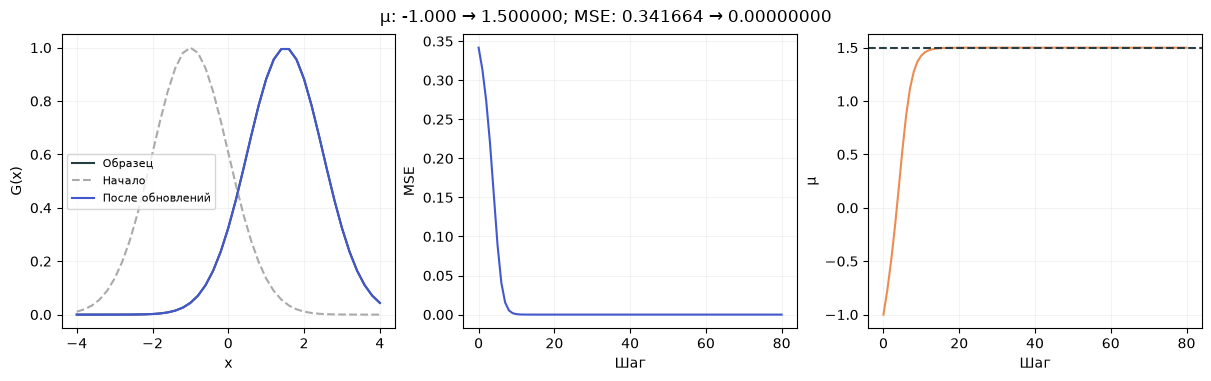

In [9]:
x = torch.linspace(-4, 4, 41, dtype=torch.float64)
target_curve = torch.exp(-0.5 * (x - 1.5).square())
center = torch.tensor(-1.0, dtype=torch.float64, requires_grad=True)
optimizer = torch.optim.SGD([center], lr=2.0)
trace = []
for step in range(81):
    optimizer.zero_grad(set_to_none=True)
    predicted = torch.exp(-0.5 * (x - center).square())
    mse = (predicted - target_curve).square().mean()
    trace.append((step, center.item(), mse.item()))
    if step == 80:
        break
    mse.backward()
    optimizer.step()

for step, position, error in trace[::20]:
    print(f"step={step:2d}  mu={position:.7f}  MSE={error:.9f}")
assert trace[-1][2] < trace[0][2] * 1e-6
display(learning_figure(language=LANG))

`torch.optim.SGD` хранит список изменяемых тензоров и размер шага. При `momentum=0`, как здесь по умолчанию, `optimizer.step()` выполняет знакомое «параметр минус размер шага, умноженный на градиент». Обновление уже происходит без построения графа, поэтому отдельный `no_grad()` вокруг него не нужен.

`zero_grad(set_to_none=True)` делает для всего списка то, что выше делала строка `mu.grad = None`. Порядок важен: убрать прошлые градиенты → вычислить новую картинку → измерить ошибку → получить новые градиенты → обновить параметры. У последнего состояния ошибка измеряется ещё раз без дополнительного обновления.

В названии SGD есть «stochastic», но здесь случайных выборок нет: каждый шаг использует все $41$ измерение. Это обычный градиентный спуск по всей небольшой задаче. PyTorch предоставляет его через тот же класс. Параметры класса перечислены в [документации SGD](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html).

Autograd не гарантирует, что ошибка на каждом шаге упадёт, и не выбирает размер шага. Если центр далеко за пределами образца, гауссиана почти нигде не видна, экспонента мала и её градиент тоже мал. В таком месте даже правильный градиент может почти не двигать модель. Восстановление зависит и от начального положения.

## 9. Несколько опытов с объяснением

**Сначала один шаг.** При исходном центре $-1$ и $\eta=2$ ошибка должна уменьшиться, а центр — уйти вправо. Значение после одного шага не обязано сразу стать $1.5$.

**Затем размер шага.** При $\eta=0$ все состояния совпадают. При увеличении $\eta$ сначала можно быстрее добраться до нужного центра, а затем получить перескоки и рост ошибки. Один и тот же большой шаг может вести себя по-разному в начале и около минимума: кривизна меняется.

**Наконец исходное положение.** Центр $-3$ начинает дальше от образца, чем $-1$. Совпадающее количество обновлений не обязано дать совпадающее качество.

<details>
<summary>Разбор: почему градиенты не стоит оставлять между шагами</summary>

Пусть первый градиент был $-0.2$, после обновления новый стал $-0.1$. Без очистки `.grad` накопит $-0.3$. Следующее движение при $\eta=1$ окажется $+0.3$ вместо $+0.1$. Это уже другой алгоритм, которого мы не выводили. Намеренное накопление бывает полезным для больших наборов данных, но здесь нужен градиент текущей полной ошибки.

</details>

<details>
<summary>Разбор: один вес, два центра</summary>

В точке $x=1$ расстояние от центра одинаково для $\mu=0$ и $\mu=2$: смещения $1$ и $-1$, квадраты одинаковы. Оба дают $\exp(-0.5)$. Для целевого веса $0.8$ два центра тоже существуют: примерно $0.331953$ и $1.668047$. Один замер не позволяет выбрать между ними. Дополнительные точки кривой дают дополнительные ограничения.

</details>

<details>
<summary>Разбор: зачем конечные разности, если есть autograd</summary>

Autograd правильно дифференцирует выполненные операции, даже если в программе по ошибке записана не та модель. Сравнение с конечными разностями проверяет градиент этой реализации. Отдельно всё равно нужна проверка её смысла: ожидаемые значения в центре, симметрия, порядок слоёв. Совпадение двух градиентов не доказывает, что выбрана подходящая функция ошибки или достаточно данных.

</details>

Теперь одна гауссиана уже может искать своё место. В следующем уроке тот же цикл будет двигать целый набор пятен, менять их размеры и цвета и собирать изображение.